# Customer Churn Analytics Platform
## 01 — Data Understanding & Initial Data Quality

**Objective:**  
Understand the structure, quality, completeness, and business meaning of the raw customer churn dataset.

### Analysis Goals
- Load the raw dataset
- Inspect rows and columns
- Understand data types
- Identify missing values
- Detect duplicates
- Check unique values
- Validate numerical fields
- Calculate initial business KPIs

In [ ]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path

# Disply Settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
# ============================================================
# VISUALIZATION THEME
# ============================================================

plt.style.use("dark_background")

sns.set_theme(
    style="darkgrid",
    context="notebook"
)

DARK_BG = "#0F172A"
CARD_BG = "#1E293B"
TEXT_COLOR = "#F8FAFC"
GRID_COLOR = "#334155"

plt.rcParams.update({
    "figure.facecolor": DARK_BG,
    "axes.facecolor": CARD_BG,
    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": TEXT_COLOR,
    "axes.titlecolor": TEXT_COLOR,
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,
    "grid.color": GRID_COLOR,
    "text.color": TEXT_COLOR,
    "figure.titlesize": 16,
    "axes.titlesize": 14,
    "axes.labelsize": 11
})

print("Dark visualization theme configured.")

Dark visualization theme configured.


In [ ]:
# ============================================================
# DATA PATH
# ============================================================

DATA_PATH = Path("../data/raw/Telco-Customer-Churn.csv")

print("Data path:")
print(DATA_PATH)

Data path:
..\data\raw\Telco-Customer-Churn.csv


In [ ]:
# ============================================================
# CHECK DATA FILE
# ============================================================

if DATA_PATH.exists():
    print("Dataset file found.")
    print(f"File: {DATA_PATH}")
else:
    print("Dataset file NOT found.")
    print("Please check the file path.")

Dataset file found.
File: ..\data\raw\Telco-Customer-Churn.csv


In [5]:
# ============================================================
# LOAD RAW DATA
# ============================================================

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [6]:
# ============================================================
# DATASET SIZE
# ============================================================

rows, columns = df.shape

print(f"Rows    : {rows:,}")
print(f"Columns : {columns:,}")

Rows    : 7,043
Columns : 21


In [7]:
# ============================================================
# FIRST 5 ROWS
# ============================================================

df.head()

,CustomerID,Gender,SeniorCitizen,Partner,Dependents,Tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
# ============================================================
# LAST 5 ROWS
# ============================================================

df.tail()

,CustomerID,Gender,SeniorCitizen,Partner,Dependents,Tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [ ]:
# Missing Values

missing = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
})

missing = missing.sort_values(
    by="Missing_Count",
    ascending=False
)

missing

,Missing_Count,Missing_Percentage
CustomerID,0,0.0
Gender,0,0.0
SeniorCitizen,0,0.0
Partner,0,0.0
Dependents,0,0.0
Tenure,0,0.0
PhoneService,0,0.0
MultipleLines,0,0.0
InternetService,0,0.0
OnlineSecurity,0,0.0


In [9]:
# ============================================================
# RANDOM SAMPLE
# ============================================================

df.sample(5, random_state=42)

,CustomerID,Gender,SeniorCitizen,Partner,Dependents,Tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
185,1024-GUALD,Female,0,Yes,No,1,No,No phone service,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,24.80,24.8,Yes
2715,0484-JPBRU,Male,0,No,No,41,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),25.25,996.45,No
3825,3620-EHIMZ,Female,0,Yes,Yes,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.35,1031.7,No
1807,6910-HADCM,Female,0,No,No,1,Yes,No,Fiber optic,No,No,Yes,No,No,No,Month-to-month,No,Electronic check,76.35,76.35,Yes
132,8587-XYZSF,Male,0,No,No,67,Yes,No,DSL,No,No,No,Yes,No,No,Two year,No,Bank transfer (automatic),50.55,3260.1,No


In [10]:
# ============================================================
# DATASET STRUCTURE
# ============================================================

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")

for i, column in enumerate(df.columns, start=1):
    print(f"{i:02d}. {column}")

Dataset Shape:
(7043, 21)

Column Names:
01. CustomerID
02. Gender
03. SeniorCitizen
04. Partner
05. Dependents
06. Tenure
07. PhoneService
08. MultipleLines
09. InternetService
10. OnlineSecurity
11. OnlineBackup
12. DeviceProtection
13. TechSupport
14. StreamingTV
15. StreamingMovies
16. Contract
17. PaperlessBilling
18. PaymentMethod
19. MonthlyCharges
20. TotalCharges
21. Churn


In [11]:
# ============================================================
# DATA TYPES
# ============================================================

dtype_summary = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values
})

dtype_summary

,Column,Data_Type
0,CustomerID,str
1,Gender,str
2,SeniorCitizen,int64
3,Partner,str
4,Dependents,str
5,Tenure,int64
6,PhoneService,str
7,MultipleLines,str
8,InternetService,str
9,OnlineSecurity,str


In [12]:
# ============================================================
# DATASET INFO
# ============================================================

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        7043 non-null   str    
 1   Gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   Tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [13]:
# ============================================================
# MISSING VALUES
# ============================================================

missing = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

missing = missing.sort_values(
    by="Missing_Count",
    ascending=False
)

missing

,Missing_Count,Missing_Percentage
CustomerID,0,0.0
Gender,0,0.0
SeniorCitizen,0,0.0
Partner,0,0.0
Dependents,0,0.0
Tenure,0,0.0
PhoneService,0,0.0
MultipleLines,0,0.0
InternetService,0,0.0
OnlineSecurity,0,0.0


In [14]:
# ============================================================
# COLUMNS WITH MISSING VALUES
# ============================================================

missing_columns = missing[
    missing["Missing_Count"] > 0
]

missing_columns

,Missing_Count,Missing_Percentage


In [15]:
# ============================================================
# DUPLICATE RECORDS
# ============================================================

duplicate_count = df.duplicated().sum()

duplicate_percentage = (
    duplicate_count / len(df) * 100
)

print(f"Duplicate rows       : {duplicate_count:,}")
print(f"Duplicate percentage : {duplicate_percentage:.2f}%")

Duplicate rows       : 0
Duplicate percentage : 0.00%


In [18]:
# ============================================================
# CHECK COLUMN NAMES
# ============================================================

print("Available columns:")
print(df.columns.tolist())

Available columns:
['CustomerID', 'Gender', 'SeniorCitizen', 'Partner', 'Dependents', 'Tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [19]:
# ============================================================
# STANDARDIZE COLUMN NAMES
# ============================================================

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents', 'tenure', 'phoneservice', 'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod', 'monthlycharges', 'totalcharges', 'churn']


In [20]:
# ============================================================
# CUSTOMER ID UNIQUENESS
# ============================================================

total_rows = len(df)
unique_customers = df["customerid"].nunique()

print(f"Total rows          : {total_rows:,}")
print(f"Unique Customer IDs : {unique_customers:,}")

Total rows          : 7,043
Unique Customer IDs : 7,043


In [21]:
# ============================================================
# UNIQUE VALUE SUMMARY
# ============================================================

unique_summary = pd.DataFrame({
    "Column": df.columns,
    "Unique_Values": [
        df[column].nunique(dropna=False)
        for column in df.columns
    ]
})

unique_summary

,Column,Unique_Values
0,customerid,7043
1,gender,2
2,seniorcitizen,2
3,partner,2
4,dependents,2
5,tenure,73
6,phoneservice,2
7,multiplelines,3
8,internetservice,3
9,onlinesecurity,3


In [22]:
# ============================================================
# NUMERICAL SUMMARY
# ============================================================

numeric_summary = df.describe().T

numeric_summary

,count,mean,std,min,25%,50%,75%,max
seniorcitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
monthlycharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [23]:
# ============================================================
# CATEGORICAL VALUE SUMMARY
# ============================================================

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

for column in categorical_columns:

    print("\n" + "=" * 70)
    print(f"Column: {column}")
    print("=" * 70)

    print(
        df[column]
        .value_counts(dropna=False)
    )


Column: customerid
customerid
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

Column: gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Column: partner
partner
No     3641
Yes    3402
Name: count, dtype: int64

Column: dependents
dependents
No     4933
Yes    2110
Name: count, dtype: int64

Column: phoneservice
phoneservice
Yes    6361
No      682
Name: count, dtype: int64

Column: multiplelines
multiplelines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

Column: internetservice
internetservice
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Column: onlinesecurity
onlinesecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

Column: onlineback

C:\Users\Kunde\AppData\Local\Temp\ipykernel_18204\1400984510.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [15]:
print("CUSTOMER CHURN — INITIAL KPIs")
print("=" * 50)

total_customers = len(df)

churned_customers = (
    df["Churn"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("yes")
    .sum()
)

active_customers = total_customers - churned_customers

churn_rate = churned_customers / total_customers * 100

print(f"Total Customers   : {total_customers:,}")
print(f"Churned Customers : {churned_customers:,}")
print(f"Active Customers  : {active_customers:,}")
print(f"Churn Rate        : {churn_rate:.2f}%")

CUSTOMER CHURN — INITIAL KPIs
Total Customers   : 7,043
Churned Customers : 1,869
Active Customers  : 5,174
Churn Rate        : 26.54%


In [26]:
# ============================================================
# STANDARDIZE CHURN VALUES
# ============================================================

df["Churn_Clean"] = (
    df["churn"]
    .astype(str)
    .str.strip()
    .str.lower()
)

print(
    df["Churn_Clean"]
    .value_counts(dropna=False)
)

Churn_Clean
no     5174
yes    1869
Name: count, dtype: int64


In [27]:
# ============================================================
# INITIAL CHURN KPIs
# ============================================================

total_customers = len(df)

churned_customers = (
    df["Churn_Clean"]
    .eq("yes")
    .sum()
)

active_customers = (
    df["Churn_Clean"]
    .eq("no")
    .sum()
)

churn_rate = (
    churned_customers / total_customers * 100
)

print("CUSTOMER CHURN — INITIAL KPIs")
print("=" * 55)

print(f"Total Customers   : {total_customers:,}")
print(f"Churned Customers : {churned_customers:,}")
print(f"Active Customers  : {active_customers:,}")
print(f"Churn Rate        : {churn_rate:.2f}%")

CUSTOMER CHURN — INITIAL KPIs
Total Customers   : 7,043
Churned Customers : 1,869
Active Customers  : 5,174
Churn Rate        : 26.54%


In [28]:
# ============================================================
# CHURN DISTRIBUTION
# ============================================================

churn_distribution = (
    df["Churn_Clean"]
    .value_counts()
    .rename_axis("Churn")
    .reset_index(name="Customers")
)

churn_distribution["Percentage"] = (
    churn_distribution["Customers"]
    / total_customers
    * 100
).round(2)

churn_distribution

,Churn,Customers,Percentage
0,no,5174,73.46
1,yes,1869,26.54


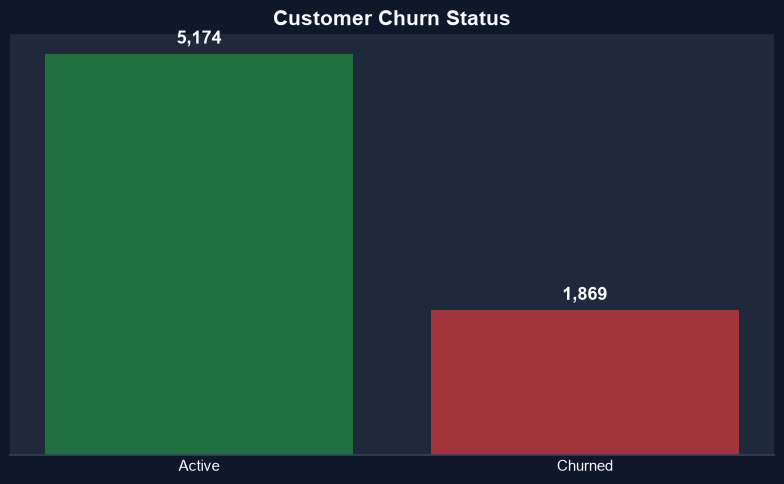

In [37]:
# ============================================================
# CUSTOMER CHURN STATUS CHART
# ============================================================

import matplotlib.pyplot as plt

# Clean Churn values
df["Churn_Clean"] = (
    df["churn"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Business-friendly labels
df["Customer_Status"] = df["Churn_Clean"].map({
    "no": "Active",
    "yes": "Churned"
})

# Count customers
Status_Counts = df["Customer_Status"].value_counts()

# Dashboard colors
Chart_Colors = [
    "#216F3F" if Status == "Active" else "#A1343C"
    for Status in Status_Counts.index
]

# Create chart
fig, ax = plt.subplots(figsize=(8, 5))

Bars = ax.bar(
    Status_Counts.index,
    Status_Counts.values,
    color=Chart_Colors,
    edgecolor="none",
    linewidth=0
)

# ============================================================
# VALUES ON EACH BAR
# ============================================================

for Bar in Bars:
    Value = Bar.get_height()

    ax.text(
        Bar.get_x() + Bar.get_width() / 2,
        Value + 80,
        f"{int(Value):,}",
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold"
    )

# ============================================================
# CLEAN DASHBOARD STYLE
# ============================================================

ax.set_title("Customer Churn Status", fontsize=15, fontweight="bold")

# Remove Y-axis
ax.set_ylabel("")
ax.set_yticks([])

# Remove borders
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

# Remove grid
ax.grid(False)

# Clean X-axis
ax.set_xlabel("")
ax.tick_params(axis="x", length=0)

plt.tight_layout()
plt.show()

In [39]:
# ============================================================
# CONTRACT DISTRIBUTION
# ============================================================

contract_distribution = (
    df["contract"]
    .value_counts()
    .rename_axis("Contract")
    .reset_index(name="Customers")
)

contract_distribution["Percentage"] = (
    contract_distribution["Customers"]
    / total_customers
    * 100
).round(2)

contract_distribution

,Contract,Customers,Percentage
0,Month-to-month,3875,55.02
1,Two year,1695,24.07
2,One year,1473,20.91


In [45]:
# ============================================================
# CELL 25 — CHURN BY CONTRACT
# ============================================================

contract_churn = (
    df.groupby("contract")
      .agg(
          Customers=("customerid", "count"),
          Churned=("Churn_Clean", lambda x: (x == "yes").sum())
      )
      .reset_index()
)

contract_churn["Churn_Rate"] = (
    contract_churn["Churned"]
    / contract_churn["Customers"]
    * 100
).round(2)

contract_churn

,contract,Customers,Churned,Churn_Rate
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


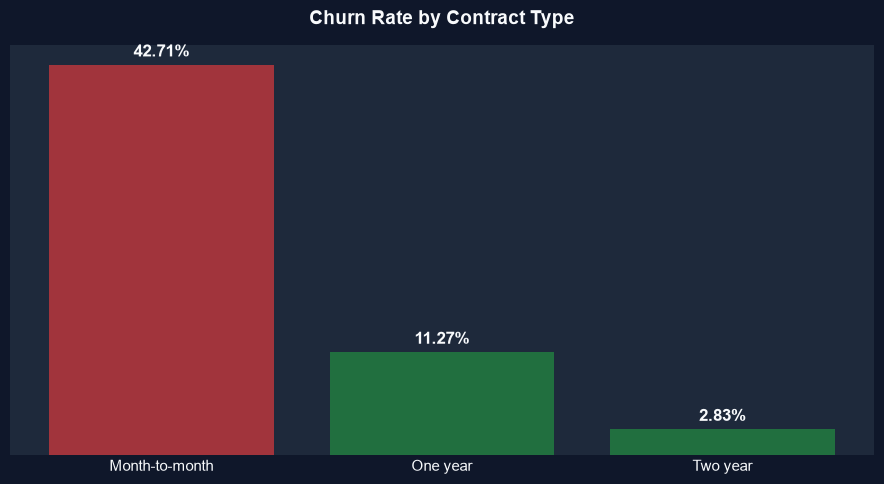

In [49]:
# ============================================================
# CHURN RATE BY CONTRACT
# ============================================================

import matplotlib.pyplot as plt

# Dashboard colors
Contract_Colors = [
    "#216F3F" if Rate < 30 else "#A1343C"
    for Rate in contract_churn["Churn_Rate"]
]

fig, ax = plt.subplots(figsize=(9, 5))

Bars = ax.bar(
    contract_churn["contract"],
    contract_churn["Churn_Rate"],
    color=Contract_Colors,
    edgecolor="none",
    linewidth=0
)

# ============================================================
# VALUES ON BARS
# ============================================================

for Bar in Bars:

    Height = Bar.get_height()

    ax.text(
        Bar.get_x() + Bar.get_width() / 2,
        Height + 0.5,
        f"{Height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

# ============================================================
# CLEAN DASHBOARD STYLE
# ============================================================

ax.set_title(
    "Churn Rate by Contract Type",
    pad=15,
    fontweight="bold"
)

ax.set_xlabel("")
ax.set_ylabel("")

# Remove Y-axis
ax.set_yticks([])
ax.spines["left"].set_visible(False)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_visible(False)

# Remove grid
ax.grid(False)

# Clean X-axis
ax.tick_params(axis="x", length=0)

plt.tight_layout()
plt.show()

In [52]:
# ============================================================
# CHURN BY GENDER
# ============================================================

gender_churn = (
    df.groupby("gender")
      .agg(
          Customers=("customerid", "count"),
          Churned=("Churn_Clean", lambda x: (x == "yes").sum())
      )
      .reset_index()
)

gender_churn["Churn_Rate"] = (
    gender_churn["Churned"]
    / gender_churn["Customers"]
    * 100
).round(2)

gender_churn

,gender,Customers,Churned,Churn_Rate
0,Female,3488,939,26.92
1,Male,3555,930,26.16


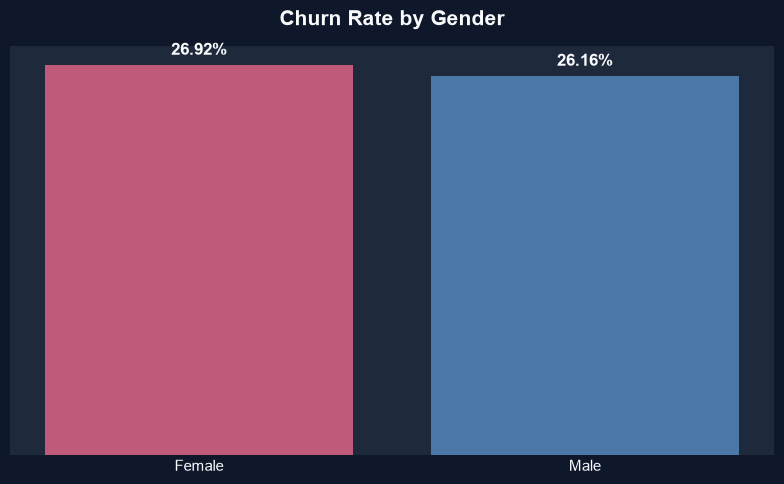

In [54]:
# ============================================================
# CELL 28 — CHURN RATE BY GENDER
# ============================================================

import matplotlib.pyplot as plt

Gender_Colors = {
    "Female": "#C05A7A",
    "Male": "#4C78A8"
}

fig, ax = plt.subplots(figsize=(8, 5))

Bars = ax.bar(
    gender_churn["gender"],
    gender_churn["Churn_Rate"],
    color=[
        Gender_Colors.get(Gender, "#777777")
        for Gender in gender_churn["gender"]
    ],
    edgecolor="none",
    linewidth=0
)

for Bar in Bars:
    Height = Bar.get_height()

    ax.text(
        Bar.get_x() + Bar.get_width() / 2,
        Height + 0.5,
        f"{Height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

ax.set_title(
    "Churn Rate by Gender",
    pad=15,
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_yticks([])

ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.spines["bottom"].set_visible(False)

ax.grid(False)
ax.tick_params(axis="x", length=0)

plt.tight_layout()
plt.show()

In [65]:
# ============================================================
# STANDARDIZE INTERNET SERVICE DISPLAY NAMES
# ============================================================

internet_churn["InternetService_Display"] = (
    internet_churn["internetservice"]
    .astype(str)
    .str.strip()
    .replace({
        "dsl": "DSL",
        "DSL": "DSL",
        "fiber optic": "Fiber Optic",
        "Fiber optic": "Fiber Optic",
        "no": "No",
        "No": "No"
    })
)

internet_churn

,internetservice,Customers,Churned,Churn_Rate,InternetService_Display
0,DSL,2421,459,18.96,DSL
1,Fiber optic,3096,1297,41.89,Fiber Optic
2,No,1526,113,7.4,No


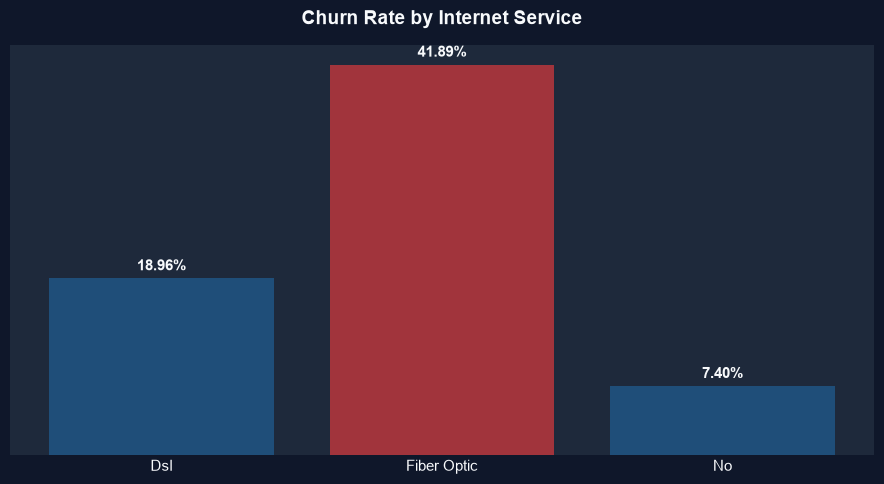

In [66]:
# ============================================================
# CHURN RATE BY INTERNET SERVICE
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5))

# Standard display labels
InternetService_Display = (
    internet_churn["internetservice"]
    .astype(str)
    .str.strip()
    .str.title()
)

# Highlight highest churn rate
Max_Churn_Index = internet_churn["Churn_Rate"].idxmax()

Bar_Colors = [
    "#A1343C" if Index == Max_Churn_Index else "#1F4E79"
    for Index in internet_churn.index
]

bars = ax.bar(
    InternetService_Display,
    internet_churn["Churn_Rate"],
    color=Bar_Colors,
    edgecolor="none",
    linewidth=0
)

ax.set_title(
    "Churn Rate by Internet Service",
    pad=15,
    fontweight="bold"
)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_yticks([])

ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.spines["bottom"].set_visible(False)

ax.grid(False)
ax.tick_params(axis="x", length=0)

# Add values on bars
for bar in bars:

    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

In [67]:
# ============================================================
# CHURN BY PAYMENT METHOD
# ============================================================

payment_churn = (
    df.groupby("paymentmethod")
      .agg(
          Customers=("customerid", "count"),
          Churned=("Churn_Clean", lambda x: (x == "yes").sum())
      )
      .reset_index()
)

payment_churn["Churn_Rate"] = (
    payment_churn["Churned"]
    / payment_churn["Customers"]
    * 100
).round(2)

# Standard display names
payment_churn["PaymentMethod_Display"] = (
    payment_churn["paymentmethod"]
    .astype(str)
    .str.strip()
    .replace({
        "electronic check": "Electronic Check",
        "mailed check": "Mailed Check",
        "bank transfer (automatic)": "Bank Transfer (Automatic)",
        "credit card (automatic)": "Credit Card (Automatic)"
    })
)

payment_churn

,paymentmethod,Customers,Churned,Churn_Rate,PaymentMethod_Display
0,Bank transfer (automatic),1544,258,16.71,Bank transfer (automatic)
1,Credit card (automatic),1522,232,15.24,Credit card (automatic)
2,Electronic check,2365,1071,45.29,Electronic check
3,Mailed check,1612,308,19.11,Mailed check


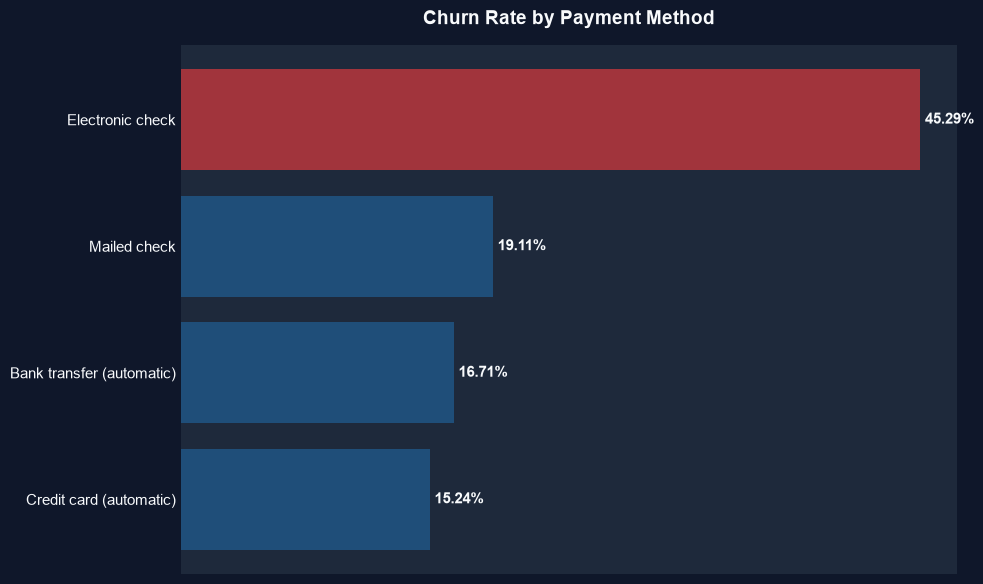

In [ ]:
# ============================================================
# CHURN RATE BY PAYMENT METHOD
# ============================================================

payment_churn = payment_churn.sort_values(
    "Churn_Rate",
    ascending=True
)

# Highlight highest churn rate
Max_Churn_Index = payment_churn["Churn_Rate"].idxmax()

Bar_Colors = [
    "#A1343C" if Index == Max_Churn_Index else "#1F4E79"
    for Index in payment_churn.index
]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    payment_churn["PaymentMethod_Display"],
    payment_churn["Churn_Rate"],
    color=Bar_Colors,
    edgecolor="none",
    linewidth=0
)

ax.set_title(
    "Churn Rate by Payment Method",
    pad=15,
    fontweight="bold"
)

ax.set_xlabel("")
ax.set_ylabel("")

# Remove Y-axis numbers
ax.set_xticks([])

# Remove borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)

ax.grid(False)

# Remove tick marks
ax.tick_params(axis="x", length=0)
ax.tick_params(axis="y", length=0)

# Add values to bars
for bar in bars:

    width = bar.get_width()

    ax.text(
        width + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center",
        ha="left",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

In [69]:
# ============================================================
# TENURE STATISTICS
# ============================================================

tenure_summary = df["tenure"].describe()

tenure_summary

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

In [70]:
# ============================================================
# AVERAGE TENURE BY CHURN
# ============================================================

tenure_by_churn = (
    df.groupby("Churn_Clean")["tenure"]
      .agg(
          ["count", "mean", "median", "min", "max"]
      )
      .round(2)
)

tenure_by_churn

,count,mean,median,min,max
Churn_Clean,,,,,
no,5174,37.57,38.0,0,72
yes,1869,17.98,10.0,1,72


In [72]:
# ============================================================
# MONTHLY CHARGES STATISTICS
# ============================================================

monthly_charges_summary = (
    df["monthlycharges"]
    .describe()
    .round(2)
)

monthly_charges_summary

count    7043.00
mean       64.76
std        30.09
min        18.25
25%        35.50
50%        70.35
75%        89.85
max       118.75
Name: monthlycharges, dtype: float64

In [73]:
# ============================================================
# MONTHLY CHARGES BY CHURN
# ============================================================

charges_by_churn = (
    df.groupby("Churn_Clean")["monthlycharges"]
      .agg(
          ["count", "mean", "median", "min", "max"]
      )
      .round(2)
)

charges_by_churn

,count,mean,median,min,max
Churn_Clean,,,,,
no,5174,61.27,64.43,18.25,118.75
yes,1869,74.44,79.65,18.85,118.35


In [76]:
# ============================================================
# TOTAL CHARGES DATA QUALITY CHECK
# ============================================================

print("Data type:")
print(df["totalcharges"].dtype)

print("\nBlank values:")
print(
    (df["totalcharges"].astype(str).str.strip() == "").sum()
)

print("\nUnique examples:")
print(
    df["totalcharges"]
    .astype(str)
    .str.strip()
    .head(20)
)

Data type:
str

Blank values:
11

Unique examples:
0       29.85
1      1889.5
2      108.15
3     1840.75
4      151.65
5       820.5
6      1949.4
7       301.9
8     3046.05
9     3487.95
10     587.45
11      326.8
12     5681.1
13     5036.3
14    2686.05
15    7895.15
16    1022.95
17    7382.25
18     528.35
19     1862.9
Name: totalcharges, dtype: str


In [83]:
# ============================================================
# NUMERICAL VALIDATION
# ============================================================

import pandas as pd

# Numerical columns
numeric_columns = [
    "seniorcitizen",
    "tenure",
    "monthlycharges"
]

# Convert columns to numeric
for column in numeric_columns:

    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# Validation
for column in numeric_columns:

    print("\n" + "=" * 60)
    print(f"Column: {column}")
    print("=" * 60)

    print(f"Min       : {df[column].min()}")
    print(f"Max       : {df[column].max()}")
    print(f"Mean      : {df[column].mean():.2f}")
    print(f"Missing   : {df[column].isna().sum()}")
    print(f"Data Type : {df[column].dtype}")


Column: seniorcitizen
Min       : 0
Max       : 1
Mean      : 0.16
Missing   : 0
Data Type : int64

Column: tenure
Min       : 0
Max       : 72
Mean      : 32.37
Missing   : 0
Data Type : int64

Column: monthlycharges
Min       : 18.25
Max       : 118.75
Mean      : 64.76
Missing   : 0
Data Type : float64


In [ ]:
# ============================================================
# BUSINESS LOGIC VALIDATION
# ============================================================

print("BUSINESS LOGIC CHECKS")
print("=" * 60)

print(
    f"Negative tenure values: "
    f"{(df['tenure'] < 0).sum()}"
)

print(
    f"Zero tenure customers: "
    f"{(df['tenure'] == 0).sum()}"
)

print(
    f"Negative MonthlyCharges: "
    f"{(df['monthlycharges'] < 0).sum()}"
)

print(
    f"Invalid Churn values: "
    f"{(~df['Churn_Clean'].isin(['yes', 'no'])).sum()}"
)

BUSINESS LOGIC CHECKS
Negative tenure values: 0
Zero tenure customers: 11
Negative MonthlyCharges: 0
Invalid Churn values: 0


In [87]:
# ============================================================
# DATA UNDERSTANDING SUMMARY
# ============================================================

print("=" * 70)
print("CUSTOMER CHURN ANALYTICS — DATA UNDERSTANDING SUMMARY")
print("=" * 70)

print(f"Total Customers      : {total_customers:,}")
print(f"Unique Customer IDs  : {unique_customers:,}")
print(f"Churned Customers    : {churned_customers:,}")
print(f"Active Customers     : {active_customers:,}")
print(f"Overall Churn Rate   : {churn_rate:.2f}%")
print(f"Duplicate Rows       : {duplicate_count:,}")

print("\nData Quality")
print("-" * 70)

print(
    f"Columns with NaN    : "
    f"{len(missing_columns)}"
)

print(
    f"Customer ID unique  : "
    f"{total_rows == unique_customers}"
)

print(
    f"Negative tenure     : "
    f"{(df['tenure'] < 0).sum()}"
)

print(
    f"Negative charges    : "
    f"{(df['monthlycharges'] < 0).sum()}"
)

print("=" * 70)

CUSTOMER CHURN ANALYTICS — DATA UNDERSTANDING SUMMARY
Total Customers      : 7,043
Unique Customer IDs  : 7,043
Churned Customers    : 1,869
Active Customers     : 5,174
Overall Churn Rate   : 26.54%
Duplicate Rows       : 0

Data Quality
----------------------------------------------------------------------
Columns with NaN    : 0
Customer ID unique  : True
Negative tenure     : 0
Negative charges    : 0
